## 1) Load the cleaned dataset

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 140)

INPUT_PATH = Path("cleaned_transformed.parquet")  # produced by the cleaning/transformation notebook

data = pd.read_parquet(INPUT_PATH)
print(f"Loaded: {data.shape[0]:,} rows, {data.shape[1]} columns")
data.head()

Loaded: 12,612,960 rows, 83 columns


,Datetime,CDWL_CW_FLOW,CDWL_PM_POW_1,CDWL_PM_POW_2,CDWL_PM_POW_3,CDWL_RW_TEMP,CDWL_SW_TEMP,CHL_CD_FLOW_1,CHL_CD_FLOW_2,CHL_CD_FLOW_3,CHL_COMP_SPD_CTRL_1,CHL_COMP_SPD_CTRL_2,CHL_COMP_SPD_CTRL_3,CHL_CW_FLOW_1,CHL_CW_FLOW_2,CHL_CW_FLOW_3,CHL_POW_1,CHL_POW_2,CHL_POW_3,CHL_SWCD_TEMP_1,CHL_SWCD_TEMP_2,CHL_SWCD_TEMP_3,CHL_RW_TEMP_1,CHL_RW_TEMP_2,CHL_RW_TEMP_3,CHL_STA_1,CHL_STA_2,CHL_STA_3,CHL_RWCD_TEMP_1,CHL_RWCD_TEMP_2,CHL_RWCD_TEMP_3,CHL_SW_TEMP_1,CHL_SW_TEMP_2,CHL_SW_TEMP_3,CT_FAN_SPD_1,CT_FAN_SPD_2,CT_FAN_SPD_3,CT_FAN_SPD_CTRL_1,CT_FAN_SPD_CTRL_2,CT_FAN_SPD_CTRL_3,CT_FLOW_1,CT_FLOW_2,CT_FLOW_3,CT_POW_1,CT_POW_2,CT_POW_3,CT_RW_TEMP_1,CT_RW_TEMP_2,CT_RW_TEMP_3,CT_STA_1,CT_STA_2,CT_STA_3,CT_SW_TEMPSPT,CT_SW_TEMP_1,CT_SW_TEMP_2,CT_SW_TEMP_3,CWL_PRI_CW_FLOW,CWL_PRI_PM_POW_1,CWL_PRI_PM_POW_2,CWL_PRI_PM_POW_3,CWL_PRI_RW_TEMP,CWL_PRI_SW_TEMP,CWL_PRI_SW_TEMPSPT,CWL_SEC_CW_FLOW,CWL_SEC_DP,CWL_SEC_DPSPT,CWL_SEC_LOAD,CWL_SEC_PM_POW_1,CWL_SEC_PM_POW_2,CWL_SEC_PM_SPD_1,CWL_SEC_PM_SPD_2,CWL_SEC_PM_STA_1,CWL_SEC_PM_STA_2,CWL_SEC_RW_TEMP,CWL_SEC_SW_TEMP,OA_TEMP,OA_TEMP_WB,TWV_CTRL,source_file,fault_type,fault_intensity,intensity_degC,intensity_pct
0,2018-01-01 01:00:00,321.582963,46.084146,0.000000e+00,0.000000e+00,69.188995,61.984875,321.582107,0.000429,0.000429,0.497262,0.0,0.0,279.324281,0.000372,0.000372,69.507398,0.0,0.0,69.17861,74.99603,74.99603,57.255424,42.227337,42.227337,1.0,0.0,0.0,62.262770,75.559970,75.559970,51.432564,42.049248,42.049248,0.341687,0.0,0.0,0.341687,0.0,0.0,318.419286,0.000222,0.000222,0.499460,0.0,0.0,69.178665,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.911266,69.697495,69.697495,279.325015,15.021188,0.000000e+00,0.000000e+00,57.262290,51.431625,53.999626,461.473576,529.201971,960.960802,22551.240,53.638358,0.000000,1.000000,0.000000,1.0,0.0,56.816963,57.150177,9.070051,10.355011,0.0,ChillerPlant.csv,fault_free,NaN,NaN,NaN
1,2018-01-01 01:01:00,321.582963,46.084146,0.000000e+00,0.000000e+00,68.880936,61.921814,321.582107,0.000429,0.000429,0.477222,0.0,0.0,279.324281,0.000372,0.000372,66.280762,0.0,0.0,68.87072,74.99603,74.99603,57.055916,42.227337,42.227337,1.0,0.0,0.0,62.199715,75.559906,75.559906,51.460247,42.049248,42.049248,0.333905,0.0,0.0,0.333905,0.0,0.0,318.419286,0.000222,0.000222,0.460999,0.0,0.0,68.870770,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.850730,69.697495,69.697495,279.325015,15.021188,3.107657e-21,1.041529e-21,57.062508,51.459260,53.999626,461.473576,529.201971,960.960802,21665.527,53.638358,0.000000,1.000000,0.000000,1.0,0.0,56.630524,56.950665,8.771828,10.040033,0.0,ChillerPlant.csv,fault_free,NaN,NaN,NaN
2,2018-01-01 01:02:00,321.582963,46.084146,3.512600e-18,1.600030e-34,68.577880,61.861610,321.582107,0.000429,0.000429,0.457744,0.0,0.0,279.324281,0.000372,0.000372,63.233582,0.0,0.0,68.56789,74.99603,74.99603,56.863213,42.227394,42.227394,1.0,0.0,0.0,62.139565,75.559906,75.559906,51.488262,42.049248,42.049248,0.327008,0.0,0.0,0.327008,0.0,0.0,318.419286,0.000222,0.000222,0.425439,0.0,0.0,68.567930,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.793000,69.697495,69.697495,279.325015,15.021188,0.000000e+00,0.000000e+00,56.869530,51.487328,53.999626,461.473576,529.201971,960.960802,20804.450,53.638358,0.000000,1.000000,0.000000,1.0,0.0,56.450570,56.757965,8.786055,10.055031,0.0,ChillerPlant.csv,fault_free,NaN,NaN,NaN
3,2018-01-01 01:03:00,321.582963,46.084146,0.000000e+00,0.000000e+00,68.299484,61.804260,321.582107,0.000429,0.000429,0.482627,0.0,0.0,279.324281,0.000372,0.000372,66.893384,0.0,0.0,68.29224,74.99603,74.99603,58.332360,42.227394,42.227394,1.0,0.0,0.0,62.082268,75.559906,75.559906,51.595047,42.049248,42.049248,0.320856,0.0,0.0,0.320856,0.0,0.0,318.419286,0.000222,0.000222,0.392423,0.0,0.0,68.292290,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.737957,69.697495,69.697495,279.325015,15.021188,0.000000e+00,0.000000e+00,58.238647,51.587250,53.999626,754.161433,864.846296,960.960802,0.000,52.330258,44.184977,1.000000,1.000000,1.0,1.0,61.190950,58.270123,8.800337,10.070026,0.0,ChillerPlant.csv,faul

## 2) Identify variables

In [2]:
# ---------------------------------------------------------------
# Define the numeric operational variables to characterize —
# excludes label/metadata columns and the four zero-variance
# columns already identified (included elsewhere for traceability,
# but uninformative for distributional summary here)
# ---------------------------------------------------------------
zero_variance_cols = ["CHL_STA_1", "CT_STA_1", "CWL_SEC_DPSPT", "CWL_SEC_PM_STA_1"]
label_and_metadata_cols = [
    "Datetime", "source_file", "fault_type", "fault_intensity",
    "intensity_degC", "intensity_pct",
]

numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
operational_cols = [c for c in numeric_cols if c not in zero_variance_cols + label_and_metadata_cols]
print(f"Operational variables to characterize: {len(operational_cols)}")

Operational variables to characterize: 73


In [3]:
# ---------------------------------------------------------------
# Class proportions — fault_type distribution
# Directly relevant to the research question: this dataset's class
# imbalance (documented earlier) shapes how detection performance
# should be evaluated later, so quantifying it formally here matters.
# ---------------------------------------------------------------
class_counts = data["fault_type"].value_counts()
class_pct = (data["fault_type"].value_counts(normalize=True) * 100).round(2)

class_summary = pd.DataFrame({
    "n_records": class_counts,
    "pct_of_dataset": class_pct,
})
print(class_summary)

# Scenario (file-level) counts, since row counts alone can overstate
# how many distinct experimental conditions exist per fault type
scenario_counts = data.groupby("fault_type")["source_file"].nunique().sort_values(ascending=False)
class_summary["n_scenarios"] = scenario_counts
print("\nWith scenario (file) counts added:")
print(class_summary)

                                       n_records  pct_of_dataset
fault_type                                                      
chiller_bias                             2102160           16.67
coolingtower_bias                        2102160           16.67
secondary_chilled_water_pressure_bias    2102160           16.67
bypass_leakage                           1576620           12.50
coolingtower_fouling                     1576620           12.50
bypass_stuck                             1051080            8.33
chiller_fouling                          1051080            8.33
fault_free                                525540            4.17
coolingtower_PI                           525540            4.17

With scenario (file) counts added:
                                       n_records  pct_of_dataset  n_scenarios
fault_type                                                                   
chiller_bias                             2102160           16.67            4
coolingtower_bi

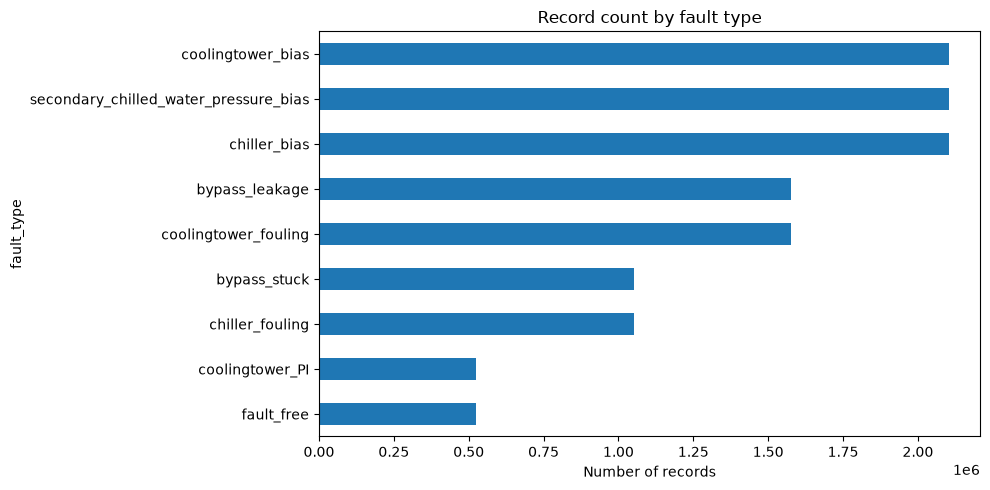

In [4]:
# ---------------------------------------------------------------
# Class proportions chart — bar chart of row counts by fault type
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
class_counts.sort_values().plot(kind="barh", ax=ax)
ax.set_xlabel("Number of records")
ax.set_title("Record count by fault type")
plt.tight_layout()
plt.show()

## 3) Dataset-level descriptive statistics

In [5]:
# ---------------------------------------------------------------
# Mean, median, std, variance, min/max, quartiles, IQR
# Core descriptive statistics for every retained operational variable,
# computed once across the full dataset to establish a baseline
# before any class-conditional breakdown
# ---------------------------------------------------------------
desc = data[operational_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
desc["variance"] = data[operational_cols].var()
desc["IQR"] = desc["75%"] - desc["25%"]
desc = desc[["mean", "50%", "std", "variance", "min", "max", "25%", "75%", "IQR"]]
desc.columns = ["mean", "median", "std", "variance", "min", "max", "Q1", "Q3", "IQR"]

print(desc.round(3))

                          mean   median         std      variance          min          max       Q1        Q3       IQR
CDWL_CW_FLOW           354.409  321.583     100.865  1.017370e+04      321.546      964.775  321.583   321.583     0.000
CDWL_PM_POW_1           20.091    7.732      17.875  3.195260e+02        3.327      142.277    7.647    46.084    38.437
CDWL_PM_POW_2            4.527    0.000      13.788  1.901200e+02        0.000      135.572    0.000     0.000     0.000
CDWL_PM_POW_3            0.157    0.000       2.714  7.363000e+00        0.000       87.297    0.000     0.000     0.000
CDWL_RW_TEMP            71.863   60.860      20.229  4.092060e+02       41.637      163.377   60.157    75.009    14.852
CDWL_SW_TEMP            70.322   60.135      19.459  3.786640e+02       41.491      162.350   60.008    72.060    12.052
CHL_CD_FLOW_1          321.583  321.582       1.484  2.201000e+00      201.784      493.760  321.582   321.582     0.000
CHL_CD_FLOW_2           31.744  

## 4) Check distribution characteristics

In [6]:
# ---------------------------------------------------------------
# Distribution characteristics — skewness and kurtosis
# Flags which variables are meaningfully non-normal, relevant given
# the multimodality already identified during the raw data assessment
# (equipment staging / load regime driving the shape of several
# temperature and flow variables)
# ---------------------------------------------------------------
dist_shape = pd.DataFrame({
    "skewness": data[operational_cols].skew(),
    "kurtosis": data[operational_cols].kurtosis(),  # excess kurtosis (0 = normal)
}).sort_values("skewness", key=abs, ascending=False)

print("Most skewed variables (top 15):")
print(dist_shape.head(15).round(3))

Most skewed variables (top 15):
                     skewness  kurtosis
CWL_PRI_PM_POW_1       60.836  8735.690
CT_POW_3               26.476   830.553
CHL_CD_FLOW_1          25.929  6168.906
CHL_CW_FLOW_1          25.929  6168.906
CHL_POW_3              18.403   352.983
CT_FAN_SPD_CTRL_3      18.264   344.377
CT_FAN_SPD_3           18.264   344.377
CHL_COMP_SPD_CTRL_3    17.992   330.678
CDWL_PM_POW_3          17.252   297.942
CT_FLOW_3              17.191   293.630
CWL_PRI_PM_POW_3       17.172   293.255
CHL_CD_FLOW_3          17.156   292.462
CHL_CW_FLOW_3          17.156   292.462
CT_STA_3               17.150   292.115
CHL_STA_3              17.150   292.115


## 5) Fault-class frequencies and proportions

In [7]:
# ---------------------------------------------------------------
# Counts/percentages by group — descriptive statistics for key
# operational variables, broken out by fault_type
# Rather than every one of the 73 operational variables, this
# focuses on a small set of physically central variables (chiller
# power, supply/return temperature, plant load) directly relevant
# to the research question of detecting/diagnosing chiller faults
# ---------------------------------------------------------------
key_vars = ["CHL_POW_1", "CHL_SW_TEMP_1", "CHL_RW_TEMP_1", "CWL_SEC_LOAD", "OA_TEMP"]

for var in key_vars:
    print(f"\n--- {var} by fault_type ---")
    print(data.groupby("fault_type")[var].agg(["mean", "median", "std", "min", "max"]).round(3))


--- CHL_POW_1 by fault_type ---
                                         mean  median     std  min      max
fault_type                                                                 
bypass_leakage                         27.746   2.417  40.793  0.0  278.911
bypass_stuck                           20.413   2.983  23.279  0.0  238.725
chiller_bias                           28.163   1.994  52.979  0.0  234.832
chiller_fouling                        37.722   2.986  68.162  0.0  241.059
coolingtower_PI                        30.501   1.941  54.852  0.0  274.451
coolingtower_bias                      28.387   1.941  51.629  0.0  234.717
coolingtower_fouling                   28.510   1.941  51.987  0.0  236.790
fault_free                             28.180   1.941  51.210  0.0  232.503
secondary_chilled_water_pressure_bias  28.152   1.941  51.127  0.0  232.444

--- CHL_SW_TEMP_1 by fault_type ---
                                         mean  median     std     min      max
fault_type     

## 6. Equipment Staging frequencies

In [8]:
# ---------------------------------------------------------------
# Frequencies — equipment staging state distribution
# Directly relevant given the earlier finding that staging regime
# (how many chillers are active) drives much of the dataset's
# underlying variability independent of fault condition
# ---------------------------------------------------------------
data["n_chillers_on"] = data[["CHL_STA_1", "CHL_STA_2", "CHL_STA_3"]].sum(axis=1)

staging_freq = data["n_chillers_on"].value_counts(normalize=False).sort_index()
staging_pct = (data["n_chillers_on"].value_counts(normalize=True) * 100).sort_index().round(2)

staging_summary = pd.DataFrame({"n_records": staging_freq, "pct_of_dataset": staging_pct})
print(staging_summary)

               n_records  pct_of_dataset
n_chillers_on                           
1.0             11367829           90.13
2.0              1202679            9.54
3.0                42452            0.34


## 7) Grouped Differences Test

In [9]:
# ---------------------------------------------------------------
# Statistical test for group differences — formal backing beyond
# the mutual-information screen, using a key physically
# central variable (chiller power) across fault types
# ---------------------------------------------------------------
groups = [grp["CHL_POW_1"].dropna().values for _, grp in data.groupby("fault_type")]
h_stat, p_val = stats.kruskal(*groups)
print(f"Kruskal-Wallis test, CHL_POW_1 across fault_type groups:")
print(f"H-statistic = {h_stat:.2f}, p-value = {p_val:.2e}")

Kruskal-Wallis test, CHL_POW_1 across fault_type groups:
H-statistic = 944701.45, p-value = 0.00e+00


## 12. Compact EDA summary table

In [10]:
# ---------------------------------------------------------------
# Summary table — important numeric variables
# Matches the requested format: Variable | Mean | Std. Dev. | Min | Median | Max
# ---------------------------------------------------------------
key_vars = ["CHL_POW_1", "CHL_SW_TEMP_1", "CHL_RW_TEMP_1", "CWL_SEC_LOAD", "OA_TEMP"]

numeric_summary = data[key_vars].agg(["mean", "std", "min", "median", "max"]).T
numeric_summary.columns = ["Mean", "Std. Dev.", "Min", "Median", "Max"]
numeric_summary = numeric_summary.round(2)
numeric_summary.index.name = "Variable"
numeric_summary = numeric_summary.reset_index()

print(numeric_summary.to_string(index=False))

     Variable     Mean  Std. Dev.         Min  Median        Max
    CHL_POW_1    28.44      50.73        0.00    2.05     278.91
CHL_SW_TEMP_1    53.60       6.41       39.75   54.00     108.01
CHL_RW_TEMP_1    55.05       6.11       39.09   54.10     108.87
 CWL_SEC_LOAD 74151.71  175946.65 -1310068.00    0.00 1984061.50
      OA_TEMP    44.91      18.50       -9.76   46.35      80.49


In [11]:
# ---------------------------------------------------------------
# Summary table — categorical variable (fault_type)
# Matches the requested format: Category | Count | Percentage
# ---------------------------------------------------------------
category_summary = pd.DataFrame({
    "Category": data["fault_type"].value_counts().index,
    "Count": data["fault_type"].value_counts().values,
    "Percentage": (data["fault_type"].value_counts(normalize=True) * 100).round(2).values,
})

print(category_summary.to_string(index=False))

                             Category   Count  Percentage
                         chiller_bias 2102160       16.67
                    coolingtower_bias 2102160       16.67
secondary_chilled_water_pressure_bias 2102160       16.67
                       bypass_leakage 1576620       12.50
                 coolingtower_fouling 1576620       12.50
                         bypass_stuck 1051080        8.33
                      chiller_fouling 1051080        8.33
                           fault_free  525540        4.17
                      coolingtower_PI  525540        4.17


In [12]:
# ------------------------------
# Display both tables as standard Pandas tables
# ------------------------------

print("Numeric Variable Summary")
display(numeric_summary)

print("\nFault Type Category Summary")
display(category_summary)

Numeric Variable Summary


,Variable,Mean,Std. Dev.,Min,Median,Max
0,CHL_POW_1,28.44,50.73,0.00,2.05,278.91
1,CHL_SW_TEMP_1,53.60,6.41,39.75,54.00,108.01
2,CHL_RW_TEMP_1,55.05,6.11,39.09,54.10,108.87
3,CWL_SEC_LOAD,74151.71,175946.65,-1310068.00,0.00,1984061.50
4,OA_TEMP,44.91,18.50,-9.76,46.35,80.49



Fault Type Category Summary


,Category,Count,Percentage
0,chiller_bias,2102160,16.67
1,coolingtower_bias,2102160,16.67
2,secondary_chilled_water_pressure_bias,2102160,16.67
3,bypass_leakage,1576620,12.50
4,coolingtower_fouling,1576620,12.50
5,bypass_stuck,1051080,8.33
6,chiller_fouling,1051080,8.33
7,fault_free,525540,4.17
8,coolingtower_PI,525540,4.17


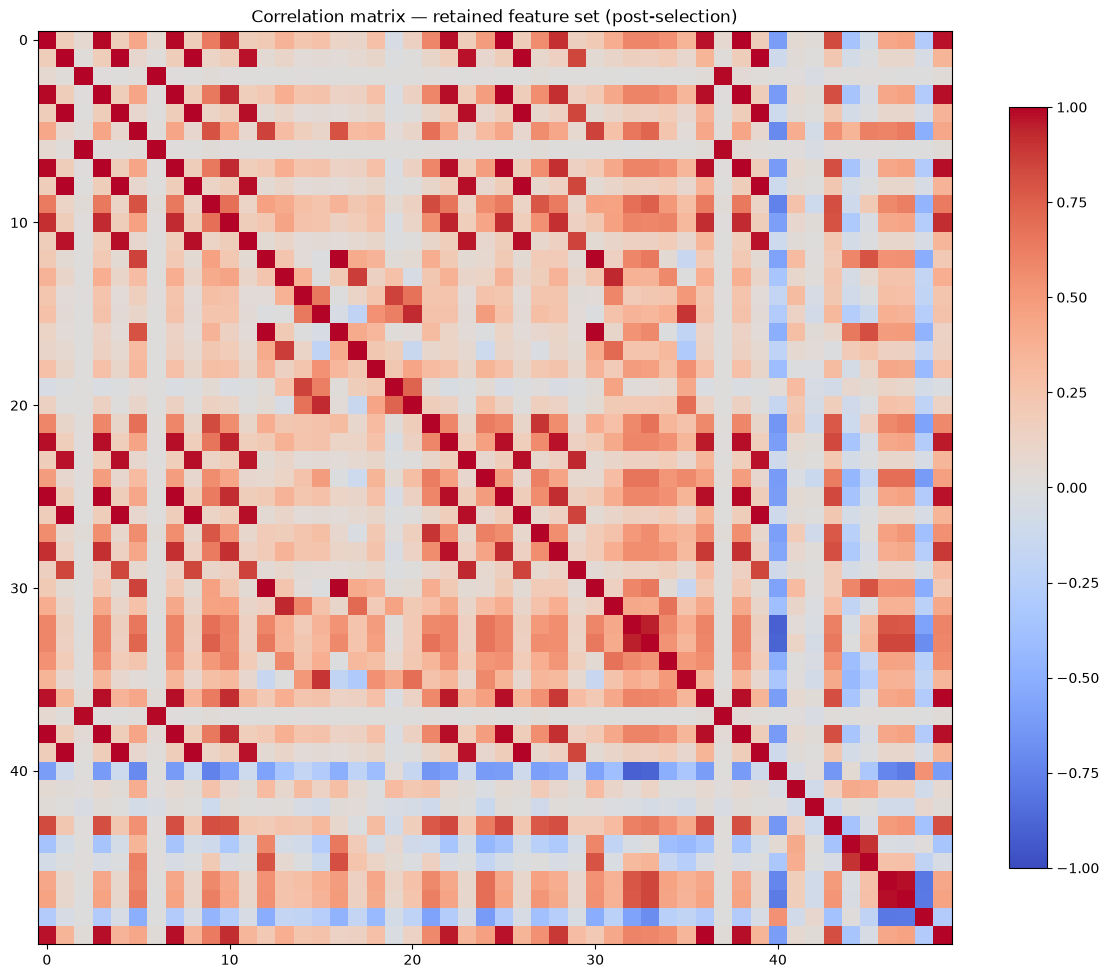

In [14]:
# ---------------------------------------------------------------
# Correlation heatmap of the retained (post-selection) feature set,
# as a visual confirmation that redundancy was meaningfully reduced
# ---------------------------------------------------------------
import json

feature_selected = pd.read_parquet("feature_selected.parquet")
with open("final_feature_cols.json") as f:
    final_feature_cols = json.load(f)

corr = feature_selected[final_feature_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_title("Correlation matrix — retained feature set (post-selection)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

In [19]:
# ---------------------------------------------------------------
# Identify the feature at the dark-blue band in the heatmap —
# negatively correlated with most of the rest of the retained set
# ---------------------------------------------------------------
avg_corr = corr.mean().sort_values()
print("Features with the most negative average correlation to the rest of the set:")
print(avg_corr.head(5))
print(f"\nFeature at index ~41: {final_feature_cols[41]}")

Features with the most negative average correlation to the rest of the set:
CWL_PRI_SW_TEMPSPT   -0.345288
TWV_CTRL             -0.224765
CWL_SEC_RW_TEMP      -0.039868
CWL_SEC_DP            0.001383
CHL_CW_FLOW_1         0.067849
dtype: float64

Feature at index ~41: CWL_SEC_CW_FLOW


In [22]:
# ---------------------------------------------------------------
# Confirm the actual index position of the most negatively-
# correlated feature, rather than guessing from the heatmap by eye
# ---------------------------------------------------------------
print(f"CWL_PRI_SW_TEMPSPT is at index: {final_feature_cols.index('CWL_PRI_SW_TEMPSPT')}")

CWL_PRI_SW_TEMPSPT is at index: 40


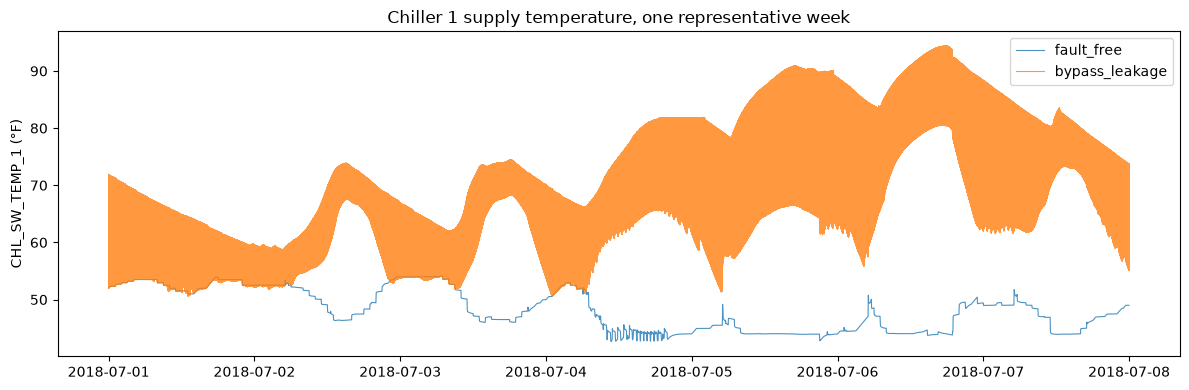

In [15]:
# ---------------------------------------------------------------
# Trend over time — one representative week, fault_free vs. a
# contrasting fault type, for a physically central variable
# ---------------------------------------------------------------
week_mask = (data["Datetime"] >= "2018-07-01") & (data["Datetime"] < "2018-07-08")

fig, ax = plt.subplots(figsize=(12, 4))
for ft in ["fault_free", "bypass_leakage"]:
    subset = data[week_mask & (data["fault_type"] == ft)].sort_values("Datetime")
    ax.plot(subset["Datetime"], subset["CHL_SW_TEMP_1"], label=ft, alpha=0.8, linewidth=0.8)

ax.set_ylabel("CHL_SW_TEMP_1 (°F)")
ax.set_title("Chiller 1 supply temperature, one representative week")
ax.legend()
plt.tight_layout()
plt.show()

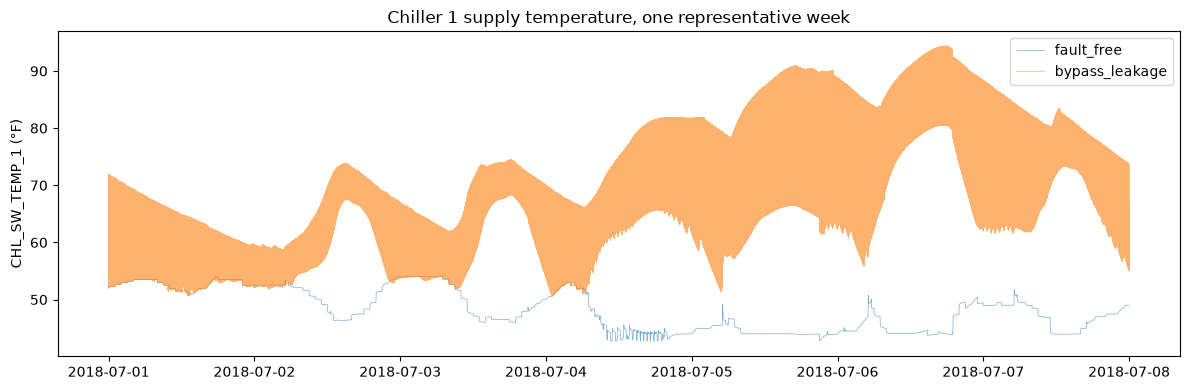

In [20]:
# ---------------------------------------------------------------
# Re-render with settings that keep the line itself visible rather
# than rendering as a solid filled band
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
for ft, color in [("fault_free", "tab:blue"), ("bypass_leakage", "tab:orange")]:
    subset = data[week_mask & (data["fault_type"] == ft)].sort_values("Datetime")
    ax.plot(subset["Datetime"], subset["CHL_SW_TEMP_1"], label=ft, color=color, linewidth=0.5, alpha=0.6)

ax.set_ylabel("CHL_SW_TEMP_1 (°F)")
ax.set_title("Chiller 1 supply temperature, one representative week")
ax.legend()
plt.tight_layout()
plt.show()

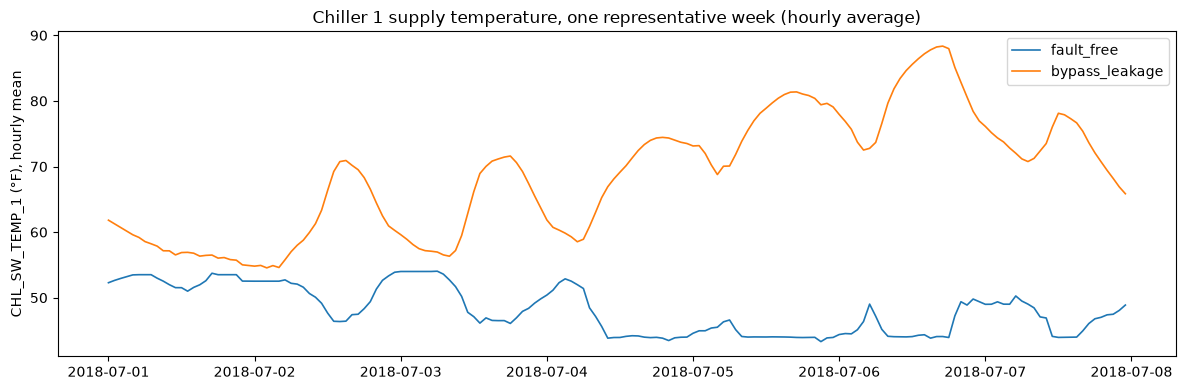

In [21]:
# ---------------------------------------------------------------
# Downsample to hourly mean to make the trend legible, while
# preserving the comparison between fault_free and bypass_leakage
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
for ft, color in [("fault_free", "tab:blue"), ("bypass_leakage", "tab:orange")]:
    subset = data[week_mask & (data["fault_type"] == ft)].sort_values("Datetime")
    hourly = subset.set_index("Datetime")["CHL_SW_TEMP_1"].resample("1h").mean()
    ax.plot(hourly.index, hourly.values, label=ft, color=color, linewidth=1.2)

ax.set_ylabel("CHL_SW_TEMP_1 (°F), hourly mean")
ax.set_title("Chiller 1 supply temperature, one representative week (hourly average)")
ax.legend()
plt.tight_layout()
plt.show()

In [17]:
# ---------------------------------------------------------------
# Cross-tabulation — staging state distribution by fault type
# ---------------------------------------------------------------
crosstab = pd.crosstab(data["fault_type"], data["n_chillers_on"], normalize="index") * 100
print(crosstab.round(2))

n_chillers_on                             1.0    2.0   3.0
fault_type                                                
bypass_leakage                          98.55   1.45  0.00
bypass_stuck                           100.00   0.00  0.00
chiller_bias                            87.80  11.77  0.43
chiller_fouling                         88.95  10.78  0.27
coolingtower_PI                         87.87  11.68  0.44
coolingtower_bias                       87.56  12.00  0.44
coolingtower_fouling                    87.56  12.00  0.44
fault_free                              87.56  12.01  0.44
secondary_chilled_water_pressure_bias   87.49  12.04  0.47


In [23]:
# ---------------------------------------------------------------
# Quantify autocorrelation in a key variable to confirm the
# independence assumption violation
# ---------------------------------------------------------------
from statsmodels.tsa.stattools import acf

sample_series = data[(data["fault_type"] == "fault_free")].sort_values("Datetime")["CHL_POW_1"]
acf_vals = acf(sample_series, nlags=60, fft=True)

print("Autocorrelation of CHL_POW_1 at selected lags (fault_free):")
for lag in [1, 5, 15, 30, 60]:
    print(f"  lag {lag} min: r = {acf_vals[lag]:.3f}")

Autocorrelation of CHL_POW_1 at selected lags (fault_free):
  lag 1 min: r = 0.994
  lag 5 min: r = 0.973
  lag 15 min: r = 0.938
  lag 30 min: r = 0.904
  lag 60 min: r = 0.882
